<a href="https://colab.research.google.com/github/divyadharshiniug/24ADI006L_24BAD023/blob/main/EX7_Text_Preprocessing_Word2Vec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EX 7: Text Preprocessing and Embedding Generation using NLP Libraries
NLTK preprocessing + Gensim Word2Vec (Skip-gram)

In [1]:
!pip install -q nltk gensim numpy

import nltk, string, numpy as np
from nltk.corpus import brown, stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.probability import FreqDist
from gensim.models import Word2Vec

nltk.download('brown')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

ROLL_NO = "24BAD23"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 41.3 MB/s eta 0:00:00


[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


## Part A: Dataset Preparation and Text Preprocessing

In [2]:
print("Roll No:", ROLL_NO)

raw_sentences = brown.sents(categories='news')
print("Total sentences:", len(raw_sentences))

print("\nSample original sentences:")
for s in raw_sentences[:3]:
    print(" ".join(s))

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(sentence):
    text = " ".join(sentence).lower()
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in string.punctuation]
    tokens = [t for t in tokens if t.isalpha()]
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return tokens

processed_sentences = [preprocess(s) for s in raw_sentences]
processed_sentences = [s for s in processed_sentences if len(s) > 0]

print("\nOriginal vs Preprocessed:")
for i in range(3):
    print("\nOriginal    :", " ".join(raw_sentences[i]))
    print("Preprocessed:", processed_sentences[i])

Roll No: 24BAD23
Total sentences: 4623

Sample original sentences:
The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary which was won by Mayor-nominate Ivan Allen Jr. .

Original vs Preprocessed:

Original    : The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
Preprocessed: ['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', '

## Part B: Vocabulary Generation and Word Frequency Analysis

Roll No: 24BAD23
Vocabulary size: 9896
Total tokens   : 47682

Top 10 most frequent words:
said            406
year            260
would           249
new             241
state           223
one             222
last            177
two             174
first           158
president       155


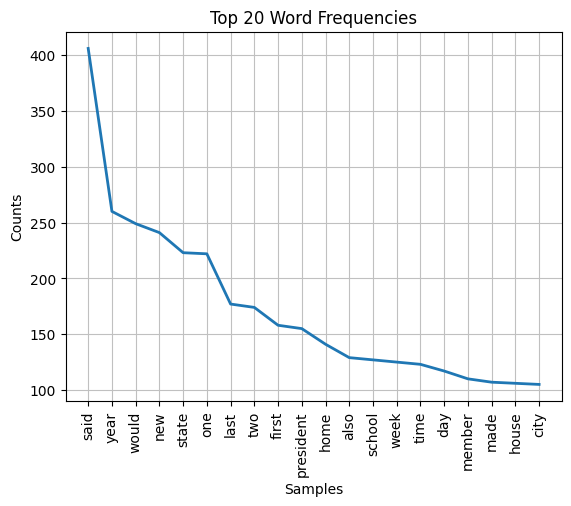


Sample tokenized sentences for Word2Vec:
[['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', 'primary', 'election', 'produced', 'evidence', 'irregularity', 'took', 'place'], ['jury', 'said', 'presentment', 'city', 'executive', 'committee', 'charge', 'election', 'deserves', 'praise', 'thanks', 'city', 'atlanta', 'manner', 'election', 'conducted'], ['term', 'jury', 'charged', 'fulton', 'superior', 'court', 'judge', 'durwood', 'pye', 'investigate', 'report', 'possible', 'irregularity', 'primary', 'ivan', 'allen']]


In [3]:
print("Roll No:", ROLL_NO)

all_words = [w for sent in processed_sentences for w in sent]
vocabulary = set(all_words)
print("Vocabulary size:", len(vocabulary))
print("Total tokens   :", len(all_words))

freq_dist = FreqDist(all_words)
print("\nTop 10 most frequent words:")
for word, count in freq_dist.most_common(10):
    print(f"{word:15s} {count}")

import matplotlib.pyplot as plt
freq_dist.plot(20, title="Top 20 Word Frequencies")
plt.show()

print("\nSample tokenized sentences for Word2Vec:")
print(processed_sentences[:3])

## Part C: Word Embedding Generation using Word2Vec (Skip-gram, dim=100, window=5)

In [4]:
print("Roll No:", ROLL_NO)

model = Word2Vec(
    sentences=processed_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    epochs=20,
    seed=42
)

print("Model vocabulary size:", len(model.wv))

word = "government" if "government" in model.wv else model.wv.index_to_key[0]
vector = model.wv[word]
print(f"\nEmbedding for '{word}':\n", vector)
print("Vector dimension:", vector.shape)

print(f"\nTop 5 words similar to '{word}':")
for w, score in model.wv.most_similar(word, topn=5):
    print(f"{w:15s} {score:.4f}")

Roll No: 24BAD23
Model vocabulary size: 5164

Embedding for 'government':
 [ 0.07705797 -0.09385922  0.2318229   0.24952462 -0.0208893  -0.29862568
  0.23559637  0.43779185  0.2356008  -0.7246845  -0.6457451  -0.08401801
  0.04189688  0.45974946  0.01606044 -0.64928997  0.02174457 -0.2666254
 -0.6518721   0.18050389  0.13855188  0.32243124 -0.36496168  0.20694567
 -0.02448145  0.28066868 -0.1632628   0.1450596  -0.322483   -0.07563174
 -0.19031674 -0.19686033 -0.21883267 -0.12166177  0.1735743  -0.35072365
  0.48807123  0.04917065 -0.15213811 -0.3361869  -0.23383284 -0.24951251
  0.07103562 -0.5556429   0.39469877  0.18907718  0.5330904   0.5994445
  0.72571886 -0.37462917  0.10285838 -0.36242762 -0.1744086   0.32647648
  0.07154816 -0.08190803 -0.17900215  0.21770303  0.20551085 -0.29855126
  0.00951813 -0.21938242 -0.13447873 -0.16646905  0.28650433 -0.1282045
 -0.21466361  0.0872008  -0.50274354 -0.25812078 -0.02916576  0.02703105
  0.04539433 -0.51762     0.0633681   0.37556043  0.

## Part D: Word Similarity Analysis

In [5]:
print("Roll No:", ROLL_NO)

candidate_pairs = [("president", "house"), ("school", "student"), ("city", "state"),
                   ("year", "week"), ("man", "woman")]
pairs = [(a, b) for a, b in candidate_pairs if a in model.wv and b in model.wv][:3]

def cosine(a, b):
    va, vb = model.wv[a], model.wv[b]
    return np.dot(va, vb) / (np.linalg.norm(va) * np.linalg.norm(vb))

scores = {}
for a, b in pairs:
    scores[(a, b)] = cosine(a, b)
    print(f"Similarity({a}, {b}) = {scores[(a, b)]:.4f}  | gensim: {model.wv.similarity(a, b):.4f}")

best = max(scores, key=scores.get)
print(f"\nMost similar pair: {best} with score {scores[best]:.4f}")

Roll No: 24BAD23
Similarity(president, house) = 0.3040  | gensim: 0.3040
Similarity(school, student) = 0.6525  | gensim: 0.6525
Similarity(city, state) = 0.0233  | gensim: 0.0233

Most similar pair: ('school', 'student') with score 0.6525
